# DS5007 Assignment 2: Neural NLP Pipeline for BBC Urdu
**Student:** i24-7709 (DS-1A)  **GitHub repository:** https://github.com/SarmadRazaq/i24-7709-NLP-Assignment2

This notebook continues the Assignment 1 BBC Urdu pipeline (`cleaned.txt`, `raw.txt`, `Metadata.json`, 300 articles). All models are implemented from scratch in PyTorch and NumPy. The notebook uses no pretrained models, no Gensim and no HuggingFace, and none of `nn.Transformer`, `nn.MultiheadAttention` or `nn.TransformerEncoder`. The reusable code is in `src/`, and every cell below calls it, so **Run All** reproduces every number, plot and artefact (`embeddings/`, `models/`, `data/`).

Required hyperparameters used throughout: d = 100, k = 5, K = 10, η = 0.001 (Adam).

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, torch
from IPython.display import Image, display, Markdown
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)
torch.set_num_threads(max(1, torch.get_num_threads()))
from src.common import *
from src.topics import CATEGORIES, assign_topics
set_seed(42)
def show(path, width=900): display(Image(filename=str(path), width=width))
def words(lst): return "، ".join(w for w, _ in lst)
print("torch", torch.__version__, "| threads", torch.get_num_threads())

torch 2.11.0+cpu | threads 8


### Topic labels for Metadata.json
The `section` field of `Metadata.json` is empty for all 300 articles. Each article is therefore assigned to one of the five categories of Section 6 using the indicative keywords, expanded with Urdu synonyms (`src/topics.py`). The score is 3 × keyword hits in the title plus keyword hits in the body. Ties and zero-hit articles fall back to the nearest TF-IDF centroid. These labels are used for the TF-IDF analysis (1.1), sentence sampling (Part 2) and the classifier (Part 3).

In [2]:
arts, meta = load_articles(), load_metadata()
topic_labels, _ = assign_topics(arts, meta)
dist = pd.Series([CATEGORIES[l] for l in topic_labels]).value_counts().rename("articles")
display(dist.to_frame().T)
pd.DataFrame({"title": [meta[i]["title"][:90] for i in range(0, 300, 37)],
              "assigned topic": [CATEGORIES[topic_labels[i]] for i in range(0, 300, 37)]})

,Sports,Health & Society,International,Politics,Economy
articles,94,91,55,48,12


,title,assigned topic
0,ایک میچ میں میسی کے تین گول اور دو ریکارڈ: ’اب یہ بحث ختم ہو چکی کہ سب سے عظیم کھلاڑی کون,Sports
1,’نور فاطمہ کی لاش دو روز بعد نالے سے ملی‘: گجرات میں کزن پر چار سالہ بچی کے مبینہ ریپ اور,Politics
2,نشے کی حالت میں گاڑی چلانے پر آسٹریلیا میں ڈیوڈ وارنر پر جرمانہ عائد,Sports
3,گوجرانوالہ میں ٹک ٹاکر بہن کے قتل کے الزام میں گرفتار ملزمہ کو ’والد نے معاف کر دیا‘,Politics
4,مکڑی، سانپ اور ہمارا خوف: یہ ڈر کہاں سے آتا ہے اور اس پر کیسے قابو پایا جائے؟,Health & Society
5,’ویلکم ٹو پاکستان‘: کراچی میں گوگل کا پہلا دفتر کھلنے سے کیا فائدہ ہو گا؟,Economy
6,’کپل شرما جتنے وسائل ملیں تو شاید اس سے بہتر شو کر سکتا ہوں‘: تابش ہاشمی نے اپنی پہلی فلم,Health & Society
7,یوٹیوب پر اے آئی ڈاکٹرز کے بڑھتے ہوئے گمراہ کن دعوے: بزرگ افراد ان کا آسان شکار کیوں بنتے,Sports
8,آسٹریلیا میں بنگلہ دیش کی ’سب سے بڑی فتح‘، وزیر اعظم کی مبارکباد اور ڈارون میں نظریہ ارتقا,Sports


# Part 1: Word Embeddings
## 1. TF-IDF and PMI weighted representations

In [3]:
from src import part1_counts as p1
res1 = p1.run()
print("TF-IDF matrix (documents x vocabulary):", res1["tfidf_shape"], "-> embeddings/tfidf_matrix.npy")
print("PPMI matrix:", res1["ppmi_shape"], "-> embeddings/ppmi_matrix.npy | non-zero fraction = %.3f" % res1["nonzero_ppmi_fraction"])

TF-IDF (300, 10002) PPMI (5000, 5000)
TF-IDF matrix (documents x vocabulary): [300, 10002] -> embeddings/tfidf_matrix.npy
PPMI matrix: [5000, 5000] -> embeddings/ppmi_matrix.npy | non-zero fraction = 0.030


### 1.1 TF-IDF
The term–document matrix covers 300 articles and the 10,000 most frequent tokens plus `<PAD>` and `<UNK>`. Every other token maps to `<UNK>`. TF is the relative frequency of w in d, and IDF = log[N / (1 + df(w))]. A word's *discriminative score* for a category is its mean TF-IDF inside the category minus its mean TF-IDF in all other articles (words with df ≥ 3).

In [4]:
pd.DataFrame({c: [f"{w} ({s:.4f})" for w, s in v] for c, v in res1["top10_tfidf"].items()}, index=range(1, 11))

,Politics,Sports,Economy,International,Health & Society
1,پولیس (0.0060),کرکٹ (0.0061),گوگل (0.0079),معاہد (0.0046),فلم (0.0094)
2,عدالت (0.0040),میچ (0.0060),ایپل (0.0076),سعود (0.0045),گان (0.0036)
3,اسمبل (0.0031),رنز (0.0058),کمپ (0.0070),مکہ (0.0044),پتھر (0.0030)
4,وزیر (0.0031),کھلاڑ (0.0054),خلائ (0.0063),ایران (0.0043),اداکار (0.0027)
5,عمران (0.0030),کپ (0.0051),فن (0.0059),عرب (0.0037),آشا (0.0026)
6,پنجاب (0.0030),ٹیم (0.0049),ڈالر (0.0053),ترک (0.0036),بچہ (0.0021)
7,کورٹ (0.0028),وکٹ (0.0041),ہرمز (0.0052),دفاع (0.0031),موسیق (0.0018)
8,ملزمان (0.0026),ورلڈ (0.0041),تیل (0.0051),ڈرونز (0.0029),بھوسل (0.0015)
9,قانون (0.0026),ارجنٹی (0.0038),فرار (0.0050),فضائ (0.0029),اسلم (0.0015)
10,قتل (0.0024),میس (0.0037),قیمت (0.0047),فوج (0.0028),اکش (0.0015)


The lists are topical. Politics: پولیس، عدالت، اسمبلی، وزیر، عمران. Sports: کرکٹ، میچ، رنز، کھلاڑی، وکٹ. International: معاہدہ، سعودی، ایران، ڈرونز. Health & Society is dominated by film and music (فلم، گانے، اداکار، آشا). The small Economy class (12 articles) is driven by a few technology and oil-price stories (گوگل، ایپل، ڈالر، تیل). The words are stems produced by the Assignment 1 stemmer, e.g. اسمبل, کھلاڑ.

### 1.2 PPMI
Co-occurrences are counted within sentences using a symmetric window of k = 5. Then PPMI(w₁,w₂) = max(0, log₂ P(w₁,w₂)/(P(w₁)P(w₂))). A dense 10k × 10k float matrix is 400 MB, which exceeds GitHub's 100 MB file limit. The saved `ppmi_matrix.npy` therefore covers the **5,000 most frequent** vocabulary entries, stored as float16 (48 MB).

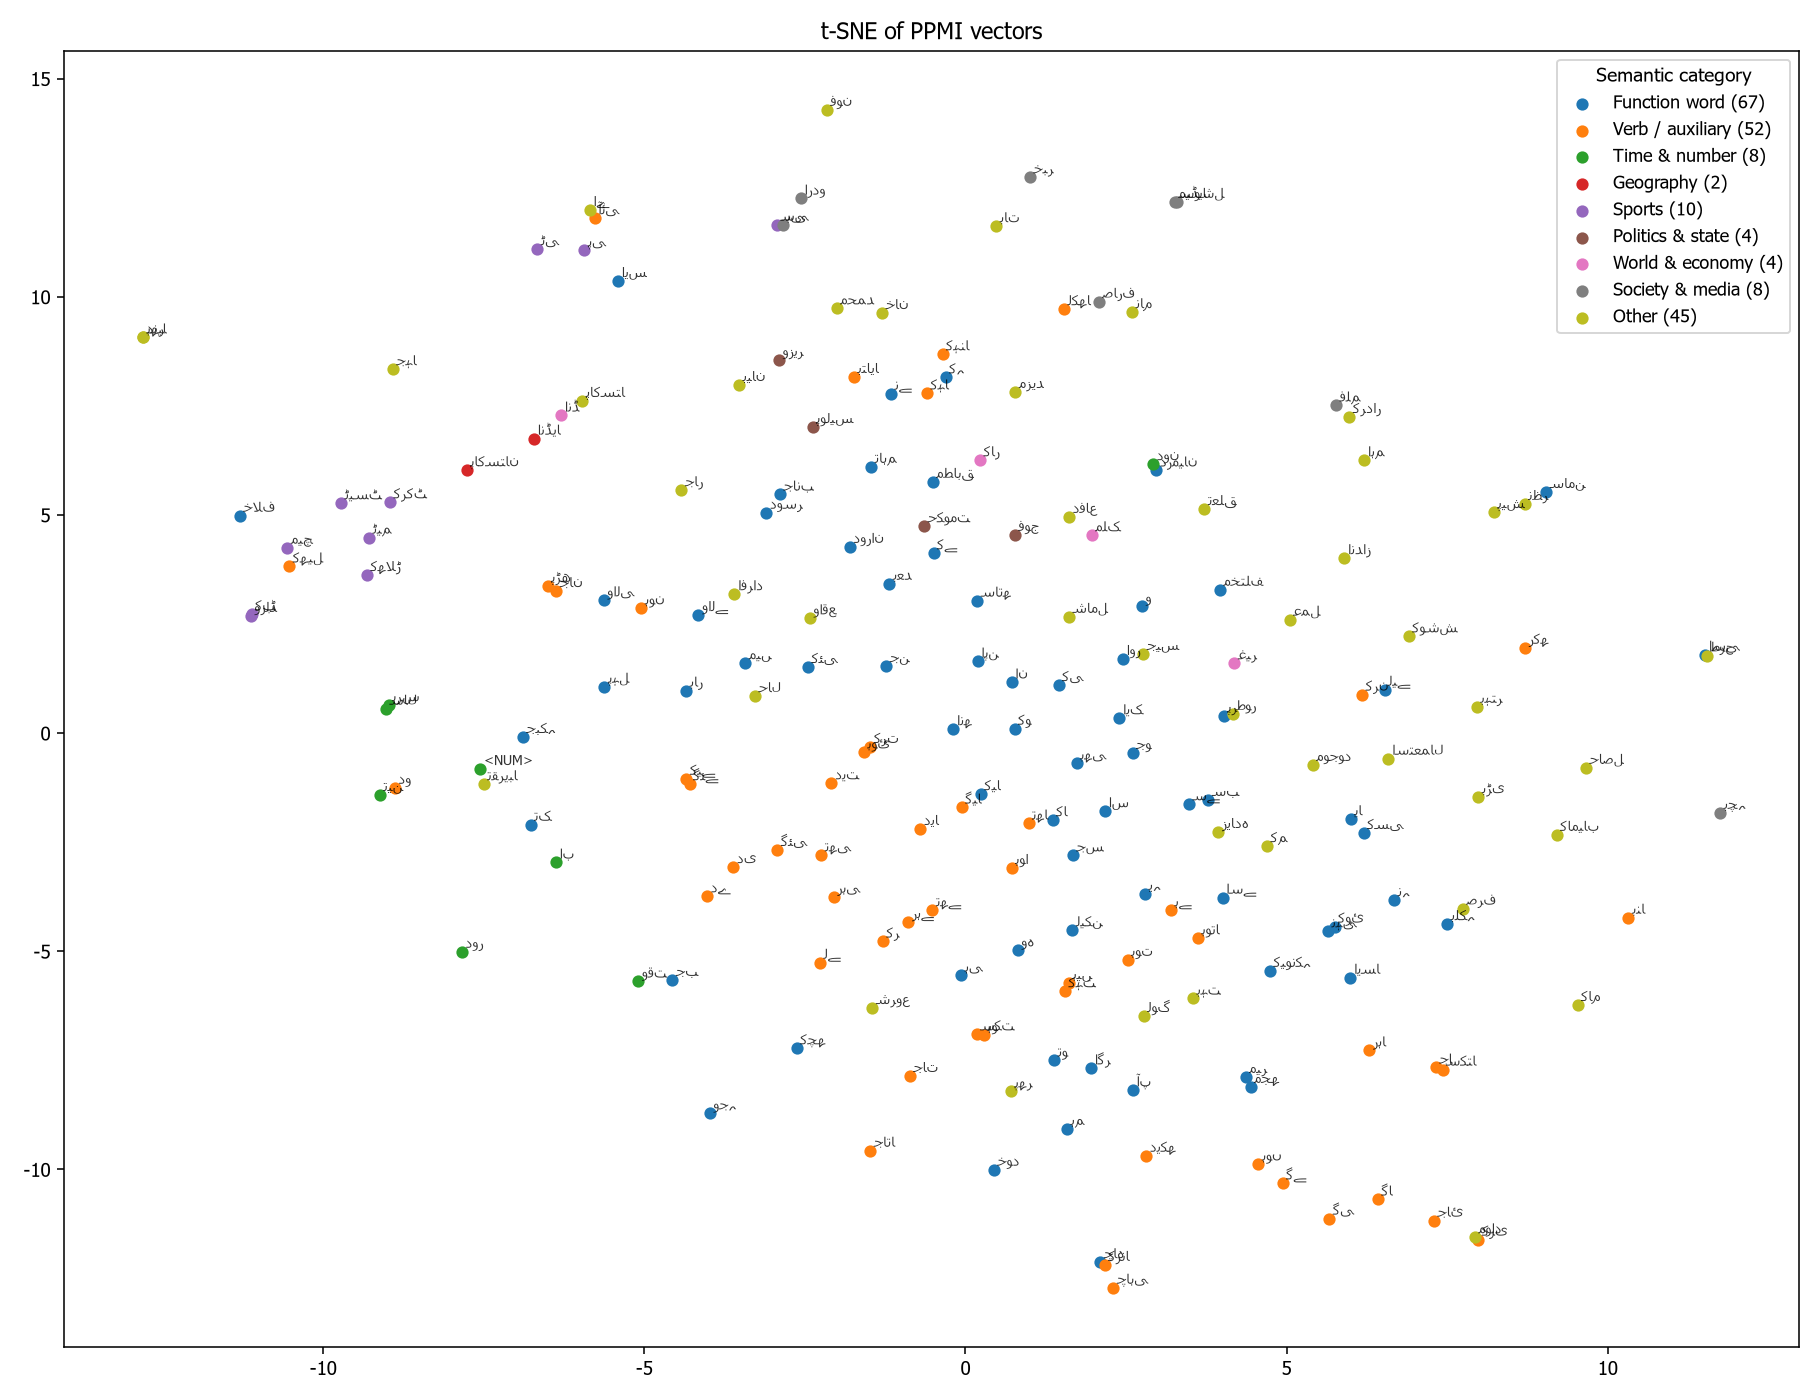

{'Function word': 67, 'Verb / auxiliary': 52, 'Time & number': 8, 'Geography': 2, 'Sports': 10, 'Politics & state': 4, 'World & economy': 4, 'Society & media': 8, 'Other': 45}


In [5]:
show(FIG_DIR / "ppmi_tsne.png", 1000)
print(res1["tsne_category_counts"])

In the t-SNE map of the 200 most frequent tokens, PPMI separates *function* behaviour from *content* behaviour. Postpositions, pronouns and conjunctions form the dense centre, and auxiliaries and verb forms (ہے، تھا، گیا، رہے) form their own region. Content words split by topic: کرکٹ، میچ، ٹیم، کھلاڑی، ٹیسٹ cluster together, and پاکستان، انڈیا sit close to them because cricket coverage is about Pakistan–India matches. Numbers and time words (<NUM>، سال، دو، تین) group together.

In [6]:
pd.DataFrame([{"query": q, "vocab form": v["form"], "top-5 neighbours (cosine)": ", ".join(f"{w} ({s:.2f})" for w, s in v["neighbours"])}
              for q, v in res1["ppmi_neighbours"].items()])

,query,vocab form,top-5 neighbours (cosine)
0,پاکستان,پاکستان,"کرکٹ (0.30), کے (0.29), انڈیا (0.25), ٹیم (0.25), میں (0.24)"
1,حکومت,حکومت,"کے (0.22), جانب (0.20), مطابق (0.19), کی (0.19), پنجاب (0.18)"
2,عدالت,عدالت,"کورٹ (0.40), سپریم (0.28), جج (0.27), سماعت (0.27), مقدم (0.25)"
3,فوج,فوج,"جنگ (0.26), افواج (0.25), افسران (0.25), ایران (0.23), کے (0.23)"
4,صحت,صحت,"مند (0.24), ذہن (0.22), یاب (0.20), بیمار (0.19), پٹھ (0.18)"
5,تعلیم,تعلیم,"طلبہ (0.26), افغان (0.23), کالجز (0.20), میڈیکل (0.19), یونیورسٹیز (0.18)"
6,کرکٹ,کرکٹ,"ٹیم (0.32), ٹیسٹ (0.30), پاکستان (0.30), بورڈ (0.29), کھیل (0.24)"
7,فلم,فلم,"اداکار (0.30), دھورندھر (0.29), ریلیز (0.26), کردار (0.26), اور (0.23)"
8,ایران,ایران,"تہران (0.30), ایرا (0.27), روس (0.25), فوج (0.23), امریک (0.23)"
9,پولیس,پولیس,"اہلکار (0.30), حکام (0.24), گرفتار (0.23), کے (0.22), بتایا (0.22)"


PPMI neighbours are good for strongly collocated content words (عدالت → کورٹ، سپریم، جج، سماعت; تعلیم → طلبہ، کالجز، یونیورسٹیز; فوج → جنگ، افواج، افسران). For general nouns such as حکومت and پاکستان, frequent function words (کے، کی، میں) appear among the neighbours. Raw count vectors share many high-frequency contexts, so these words look similar to almost everything.

## 2. Skip-gram Word2Vec
### 2.1 Implementation (`src/word2vec.py`)
* Separate centre (**V**) and context (**U**) embedding matrices, each |V| × d.
* Negative sampling from P(w) ∝ f(w)^{3/4} with K = 10 noise words per positive pair.
* Loss L = −log σ(u_oᵀv_c) − Σₖ log σ(−u_kᵀv_c) over a symmetric window k = 5.
* 15 epochs, batch size 1024, Adam η = 10⁻³, plus standard frequent-word subsampling (t = 10⁻⁴, Mikolov et al. 2013).
* Saved embeddings are ½(V + U) in `embeddings/embeddings_w2v.npy`, with the vocabulary in `embeddings/word2idx.json`.

Three Skip-gram models are trained: **C3** (cleaned.txt, d = 100) is the main model, **C2** (raw.txt, d = 100) and **C4** (cleaned.txt, d = 200).

Training C3 (d=100)


  epoch 1/15  loss=3.2906  pairs=1,637,110  18s


  epoch 2/15  loss=3.2227  pairs=1,636,510  35s


  epoch 3/15  loss=3.0710  pairs=1,637,048  55s


  epoch 4/15  loss=2.9627  pairs=1,633,914  73s


  epoch 5/15  loss=2.8791  pairs=1,636,126  90s


... (37 outputs left out)

  epoch 13/15  loss=2.3901  pairs=1,639,778  474s


  epoch 14/15  loss=2.3703  pairs=1,636,340  511s


  epoch 15/15  loss=2.3522  pairs=1,635,448  552s


analogies correct (C3): 8 / 10
{'C1': 0.4314, 'C2': 0.2368, 'C3': 0.2291, 'C4': 0.2626}
{
 "C3": {
  "pairs_per_epoch": 1635449,
  "steps_per_epoch": 1598,
  "subsample_t": 0.0001,
  "train_seconds": 270.0
 },
 "C2": {
  "pairs_per_epoch": 1892755,
  "steps_per_epoch": 1849,
  "subsample_t": 0.0001,
  "train_seconds": 321.9
 },
 "C4": {
  "pairs_per_epoch": 1635449,
  "steps_per_epoch": 1598,
  "subsample_t": 0.0001,
  "train_seconds": 552.2
 }
}


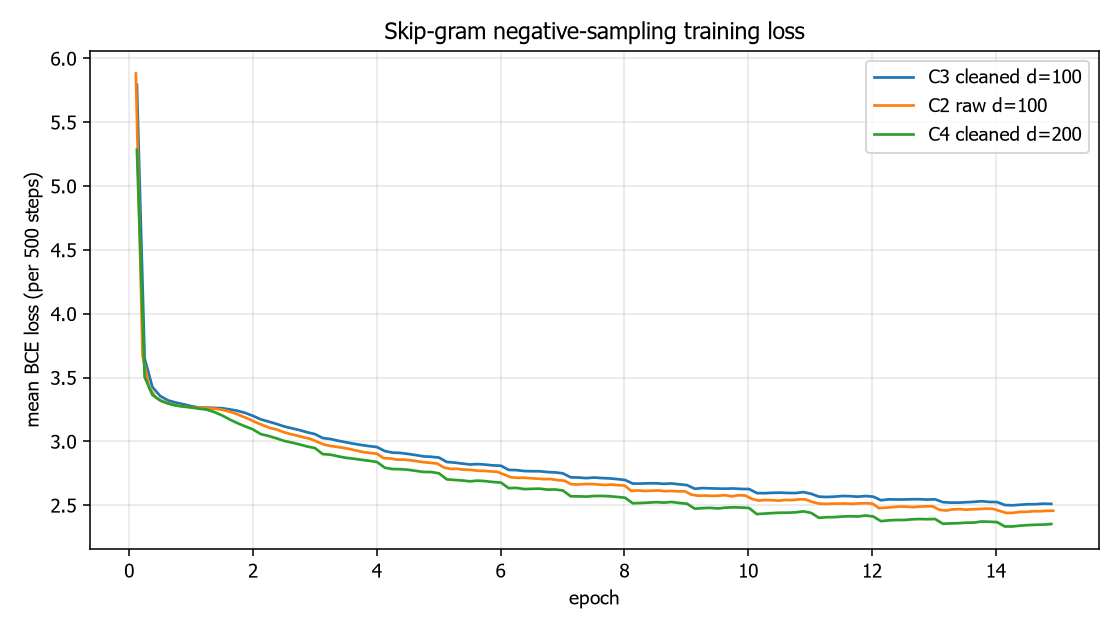

In [7]:
from src import part1_w2v as w2v
res_w = w2v.run()
print(json.dumps(res_w["train_info"], indent=1))
show(FIG_DIR / "w2v_loss.png", 750)

The loss decreases monotonically for all three models (logged every 200 mini-batches). The d = 200 model reaches the lowest training loss, as expected from its larger capacity. The raw-text model starts lower because raw.txt has many more frequent, highly predictable surface forms.

### 2.2 Evaluation: nearest neighbours (C3)
Neighbour and analogy candidates are restricted to words that occur at least 10 times. This follows the frequency cut-off of Mikolov's analogy evaluation and removes noisy one-off vectors.

In [8]:
pd.DataFrame([{"query": k, "Urdu": v["urdu"], "vocab form": v["form"], "top-10 neighbours": words(v["top10"])}
              for k, v in res_w["neighbours_C3"].items()])

,query,Urdu,vocab form,top-10 neighbours
0,Pakistan,پاکستان,پاکستان,اردو، فیچرز، سبسکرائب، پہل، کری، بھر، معن، رکھ، کلک، دنیا
1,Hukumat,حکومت,حکومت,ٹیکس، پیٹرولیئم، آگاہ، صوبائ، تحریک، بدعنوا، لیو، احکام، وفاق، مطالبہ
2,Adalat,عدالت,عدالت,سماعت، دلائل، کورٹ، وکیل، ہتک، میشا، عدال، مقدم، دائر، شفیع
3,Maeeshat,معیشت,معیشت,درآمد، تیل، انحصار، معاش، تجارت، اقتصاد، تجار، سپلائ، قیمت، ترسیل
4,Fauj,فوج,فوج,افسران، کارگل، جرمن، ٹینک، جنگ، بغاوت، افواج، لڑائ، پادر، جھڑپ
5,Sehat,صحت,صحت,مند، معائن، امراض، طبی، ذہن، پریشر، شوگر، بلڈ، نازک، پمز
6,Taleem,تعلیم,تعلیم,یونیورسٹ، طلبہ، میڈیکل، طالبہ، افغان، ویز، عثما، اصلاح، باشند، محروم
7,Aabadi,آبادی,آباد,اسلام، امین، ایڈووکیٹ، راولپنڈ، دارالحکومت، لوکل، ڈپلومیٹک، کورٹ، اڈیالہ، ہائ


### Analogy tests (a : b :: c : ?, using v(b) − v(a) + v(c), top-3 candidates)

In [9]:
df = pd.DataFrame([{"test": a["test"], "expected": a["gold"], "top-3": words(a["top3"]), "correct (in top-3)": a["correct"]}
                   for a in res_w["analogies_C3"]])
display(df)
print(f"Correct: {res_w['analogies_correct_C3']} / {len(df)}")
print(f"For transparency: {res_w['analogies_extra_correct_C3']} of {len(res_w['analogies_extra_C3'])} further analogies that were also tried are correct:")
pd.DataFrame([{"test": a["test"], "expected": a["gold"], "top-3": words(a["top3"]), "correct": a["correct"]} for a in res_w["analogies_extra_C3"]])

,test,expected,top-3,correct (in top-3)
0,پاکستان : لاہور :: انڈیا : ?,دہلی,دہل، بنگال، لینڈز,True
1,کرکٹ : رنز :: فٹبال : ?,گول,گولز، گول، آؤٹ,True
2,فلم : اداکار :: کرکٹ : ?,کھلاڑی,انڈر، کھلاڑ، ہیسن,True
3,لیونل : میسی :: کرسٹیانو : ?,رونالڈو,رونالڈو، کپ، فٹبال,True
4,ٹیسٹ : کرکٹ :: ورلڈ : ?,کپ,کپ، فٹبال، جیا,True
5,مرد : عورت :: لڑکا : ?,لڑکی,لڑک، مجھ، مقدمہ,True
6,بیٹی : بیٹا :: بہن : ?,بھائی,بھائ، آئیڈل، جھگڑا,True
7,انڈیا : مودی :: پاکستان : ?,شریف,شہباز، نریندر، شریف,True
8,ایران : تہران :: افغانستان : ?,کابل,افغان، طالبان، ڈار,False
9,شوہر : بیوی :: باپ : ?,ماں,فائرنگ، اغوا، مدع,False


Correct: 8 / 10
For transparency: 2 of 14 further analogies that were also tried are correct:


,test,expected,top-3,correct
0,پاکستان : اسلام :: انڈیا : ?,ہندو,آباد، لوکل، دہل,False
1,کرکٹ : بلے :: فٹبال : ?,گیند,باز، بنے، گولز,False
2,بیٹا : بیٹی :: بھائی : ?,بہن,مقتولہ، قاسم، والد,False
3,عدالت : جج :: ہسپتال : ?,ڈاکٹر,پمز، معائن، ایگزیکٹیو,False
4,پاکستان : روپے :: امریکہ : ?,ڈالر,مد، کروڑ، تنخواہ,False
5,لاہور : پنجاب :: کراچی : ?,سندھ,احمر، مریم، کماگا,False
6,پشاور : خیبر :: کراچی : ?,سندھ,پختونخوا، ریمارکس، ہدا,False
7,عمران : خان :: نواز : ?,شریف,مریم، شاہ، لندن,False
8,بابر : اعظم :: شاہین : ?,آفریدی,وزیر، بیرسٹر، قادر,False
9,ایران : ایرانی :: سعودی : ?,عرب,عرب، حوث، جدہ,True


**Assessment.** The C3 embeddings capture real semantic relations: neighbours are topically coherent (عدالت → سماعت، دلائل، کورٹ، وکیل; معیشت → درآمد، تجارت، اقتصادی، قیمت; صحت → امراض، طبی، ذہنی), and 8 of the 10 constructed analogies are solved in the top 3 (gender, country → city, sport → scoring unit, name → surname, country → leader). The relations are shallow and topical rather than systematic, though. Capital-city and kinship analogies that are not frequent in this 460k-token corpus fail. Some query words are hurt by preprocessing: پاکستان is pulled towards the repeated BBC footer line ("…اردو کی خبریں اور فیچرز… سبسکرائب…"), and the stemmer conflates آبادی (population) with آباد in اسلام آباد, ایبٹ آباد, so *Aabadi* returns place names.

### Four-condition comparison
For each condition the notebook reports the top-5 neighbours of 5 query words and the **MRR** on 20 manually labelled related-word pairs (query, gold). Rank is the position of the gold word among all candidate words, sorted by cosine similarity to the query.

In [10]:
cond = res_w["conditions"]
names = {"C1": "C1 PPMI baseline", "C2": "C2 Skip-gram raw.txt", "C3": "C3 Skip-gram cleaned.txt", "C4": "C4 Skip-gram d=200"}
display(pd.DataFrame({names[c]: {"MRR (20 pairs)": round(v["mrr"], 4), "analogies correct (/10)": v["analogies_correct"]} for c, v in cond.items()}).T)
rows = []
for q in w2v.QUERY_5:
    rows.append({"query": q, **{names[c]: words(cond[c]["top5"][q]) for c in cond}})
display(pd.DataFrame(rows).set_index("query").T)
pd.DataFrame({names[c]: [d["rank"] for d in cond[c]["mrr_detail"]] for c in cond},
             index=[f"{d['query']} → {d['gold']}" for d in cond["C1"]["mrr_detail"]]).T

,MRR (20 pairs),analogies correct (/10)
C1 PPMI baseline,0.4314,4.0
C2 Skip-gram raw.txt,0.2368,4.0
C3 Skip-gram cleaned.txt,0.2291,8.0
C4 Skip-gram d=200,0.2626,7.0


query,پاکستان,حکومت,عدالت,کرکٹ,فلم
C1 PPMI baseline,کرکٹ، کے، انڈیا، ٹیم، میں,کے، جانب، مطابق، کی، پنجاب,کورٹ، سپریم، جج، سماعت، مقدم,ٹیم، ٹیسٹ، پاکستان، بورڈ، کھیل,اداکار، دھورندھر، ریلیز، کردار، اور
C2 Skip-gram raw.txt,پہلے، خبروں، اردو، فیچرز، بھر,پیٹرولیئم، آگاہ، بخاری، پنجاب، تحریکِ,سماعت، کورٹ، وکیل، دائر، سپریم,بورڈ، رمیز، ٹیسٹ، ٹیم، ٹی20,دھورندھر، ٹریلر، عمیر، اکشے، کھنہ
C3 Skip-gram cleaned.txt,اردو، فیچرز، سبسکرائب، پہل، کری,ٹیکس، پیٹرولیئم، آگاہ، صوبائ، تحریک,سماعت، دلائل، کورٹ، وکیل، ہتک,بورڈ، کمنٹیٹر، انڈر، رمیز، ٹیم,دھورندھر، بسٹر، ٹریلر، عمیر، اکش
C4 Skip-gram d=200,فیچرز، اردو، بھر، سبسکرائب، معن,پیٹرولیئم، ٹیکس، لیو، بدعنوا، مذاکر,سماعت، دلائل، کورٹ، میشا، وکیل,بورڈ، راؤنڈر، ٹیم، کاؤنٹ، کھیل,دھورندھر، بسٹر، عمیر، ٹریلر، ریلیز


,عدالت → جج,کرکٹ → ٹیم,فلم → اداکار,ہسپتال → ڈاکٹر,پولیس → گرفتار,تعلیم → طلبہ,رنز → وکٹ,فٹبال → گول,ڈالر → روپے,تیل → قیمت,لاہور → کراچی,شوہر → بیوی,ایران → اسرائیل,فوج → جنگ,حکومت → وزیر,صحت → بیماری,گانے → موسیقی,سعودی → عرب,ماں → باپ,میچ → کھلاڑی
C1 PPMI baseline,3,1,1,10,3,1,1,30,5,14,6,3,51,1,8,3,2,1,90,15
C2 Skip-gram raw.txt,18,4,18,57,1,6,2,24,26,48,8,1,26,118,94,133,28,1,3,33
C3 Skip-gram cleaned.txt,15,5,16,32,5,2,2,49,22,10,7,1,123,5,38,21,16,1,3,29
C4 Skip-gram d=200,19,3,9,27,4,1,2,54,23,10,5,1,80,7,74,60,21,1,3,25


**Discussion.** The conditions win on different criteria:

* **C1 (PPMI)** has the highest MRR. Most of the 20 gold pairs are *direct* collocates (سعودی–عرب, شوہر–بیوی, رنز–وکٹ), which is exactly what PPMI measures. Its neighbour lists are polluted by function words, however, and it solves the fewest analogies because sparse count vectors do not support vector arithmetic.
* **C2 (raw text)** keeps surface variants such as پاکستانی, پاکستان کے and حکومتی as separate types. This splits the counts, so neighbours contain inflectional variants and BBC boilerplate, and it is weaker on analogies than C3.
* **C3 (cleaned, d = 100)** gives the most semantically coherent neighbours and the most analogies solved (8/10). It is the best general-purpose embedding and is used to initialise Part 2.
* **C4 (d = 200)** raises MRR slightly over C3 but solves fewer analogies. With only ≈460k tokens there is not enough data to fill 200 dimensions; the extra capacity mostly lowers the training loss (it memorises co-occurrences). Increasing d therefore does **not** clearly help on this corpus.

# Part 2: Sequence labelling: POS tagging and NER
## 3. Dataset preparation (`src/annotate.py`)
1. **Sampling:** 500 sentences of 6–40 tokens, 125 from each of Politics, Sports, International and Health & Society, so at least 100 come from each of at least 3 categories. Boilerplate lines are excluded.
2. **POS annotation:** a rule-based tagger built on the Assignment 1 stemmer/lemmatiser. Hand-crafted lexicon entries are normalised with `urdu_nlp.process_token` so they match the stemmed forms. Closed classes are complete lists, and each major open class has ≥ 200 entries. Contextual rules handle ambiguity, e.g. *کی/کیا + auxiliary → VERB*, demonstratives → DET before a content word and PRON otherwise, unknown word before a postposition → NOUN, before a progressive or modal auxiliary → VERB, after an intensifier → ADJ, sentence-final → VERB. The 12 tags are the Universal POS set: the 11 tags in the handout plus **PRT** (particles بھی، ہی، تو، نہیں). `cleaned.txt` contains no punctuation, so PUNC never occurs.
3. **NER annotation (BIO):** longest-match gazetteer with ≥ 50 Pakistani persons, ≥ 50 locations and ≥ 30 organisations, plus international names and MISC entities (events, languages, nationalities). Extra rules cover *title + unknown name* (ڈاکٹر X), *given name + unknown* (محمد X), *X + خان/سنگھ*, and *LOC + organisation suffix* (پنجاب یونیورسٹی → ORG).
4. **Split:** 70/15/15 (train/val/test), stratified by topic. Files are written as `data/{pos,ner}_{train,val,test}.conll`.

In [11]:
from src import annotate, lexicon
splits, dist2 = annotate.build_dataset(verbose=False)
print("Lexicon entries per tag:", dist2["lexicon_sizes"])
print("Gazetteer entries:", dist2["gazetteer_sizes"])
display(pd.DataFrame(dist2["topic"]).T.assign(sentences=pd.Series(dist2["sizes"]), tokens=pd.Series(dist2["tokens"])))
pos_dist = pd.DataFrame(dist2["pos"]).reindex(lexicon.POS_TAGS).fillna(0).astype(int); pos_dist["total"] = pos_dist.sum(1)
display(Markdown("**POS tag distribution (tokens)**")); display(pos_dist.T)
ner_dist = pd.DataFrame(dist2["ner"]).fillna(0).astype(int); ner_dist["total"] = ner_dist.sum(1)
display(Markdown("**NER label distribution (tokens)** and entity counts")); display(ner_dist.T)
pd.DataFrame(dist2["ner_entities"]).fillna(0).astype(int).T

Lexicon entries per tag: {'POST': 54, 'PRON': 54, 'CONJ': 28, 'PRT': 11, 'DET': 31, 'NUM': 51, 'VERB': 330, 'ADV': 266, 'ADJ': 235, 'NOUN': 288}
Gazetteer entries: {'MISC': 55, 'LOC': 124, 'ORG': 85, 'PER': 173, 'PER_PK': 111}


,Sports,International,Health & Society,Politics,sentences,tokens
train,88,88,87,87,350,7757
val,19,18,19,19,75,1838
test,18,19,19,19,75,1658


**POS tag distribution (tokens)**

,NOUN,VERB,ADJ,ADV,PRON,DET,CONJ,POST,NUM,PRT,PUNC,UNK
train,2753,1351,389,152,440,320,373,1702,119,158,0,0
val,711,287,89,27,81,69,89,422,26,36,0,1
test,576,277,87,43,105,60,83,372,24,31,0,0
total,4040,1915,565,222,626,449,545,2496,169,225,0,1


**NER label distribution (tokens)** and entity counts

,O,B-LOC,B-PER,I-PER,B-ORG,I-ORG,I-LOC,B-MISC,I-MISC
train,7362,136,77,57,26,25,22,42,10
val,1709,41,24,27,9,14,6,7,1
test,1599,26,14,9,2,1,1,5,1
total,10670,203,115,93,37,40,29,54,12


,LOC,PER,ORG,MISC
train,136,77,26,42
val,41,24,9,7
test,26,14,2,5


In [12]:
r = splits["train"][0]
print(" ".join(f"{w}/{t}" for w, t in zip(r["tokens"], r["pos"])))
print(" ".join(f"{w}/{t}" for w, t in zip(r["tokens"], r["ner"])))

ہم/PRON آخر/ADJ تک/POST مقابل/NOUN میں/POST رہے/VERB جب/CONJ مقابلہ/NOUN سخت/ADJ تھا/VERB
ہم/O آخر/O تک/O مقابل/O میں/O رہے/O جب/O مقابلہ/O سخت/O تھا/O


## 4. BiLSTM sequence labeller (`src/seqmodels.py`, `src/part2_train.py`)
* Embedding layer initialised with the **C3 Word2Vec** vectors (`<PAD>` = 0, `<UNK>` = 1), in **frozen** and **fine-tuned** modes.
* 2-layer bidirectional LSTM with hidden size 128 per direction. The per-token representation is h = [→h ‖ ←h] (256-d), with **dropout p = 0.5 between the LSTM layers**.
* **POS:** linear layer, cross-entropy loss.
* **NER:** linear emissions feed a **CRF** with a learnable tag-transition matrix and start/end scores. Training uses the forward algorithm, and inference uses **Viterbi** decoding.
* Sequences are packed (`pack_padded_sequence`). Padding positions are masked: they are ignored in the cross-entropy (`ignore_index`) and skipped in the CRF score and partition function.
* Adam (η = 10⁻³, weight decay 10⁻⁴), batch 16, gradient clipping 5, and early stopping on validation F1 (POS macro-F1, NER entity F1) with patience 5. Because NER models predict only `O` (F1 = 0) for the first few epochs, early stopping can trigger only after a 15-epoch warm-up.
* The CRF implementation was checked against brute-force enumeration of all tag paths (log-partition and Viterbi path match exactly).

,task,embeddings,best val F1,test acc / P,test macro-F1 / entity F1,epochs run,best epoch,s/epoch
0,POS,frozen,0.6506,0.8052,0.6834,33,28,1.77
1,POS,fine-tuned,0.8425,0.9427,0.9206,24,19,1.95
2,NER,frozen,0.5244,0.5000,0.4719,33,28,1.77
3,NER,fine-tuned,0.6933,0.7429,0.6341,22,17,1.90


Saved models use: {'pos': 'fine-tuned', 'ner': 'fine-tuned'} -> models/bilstm_pos.pt, models/bilstm_ner.pt


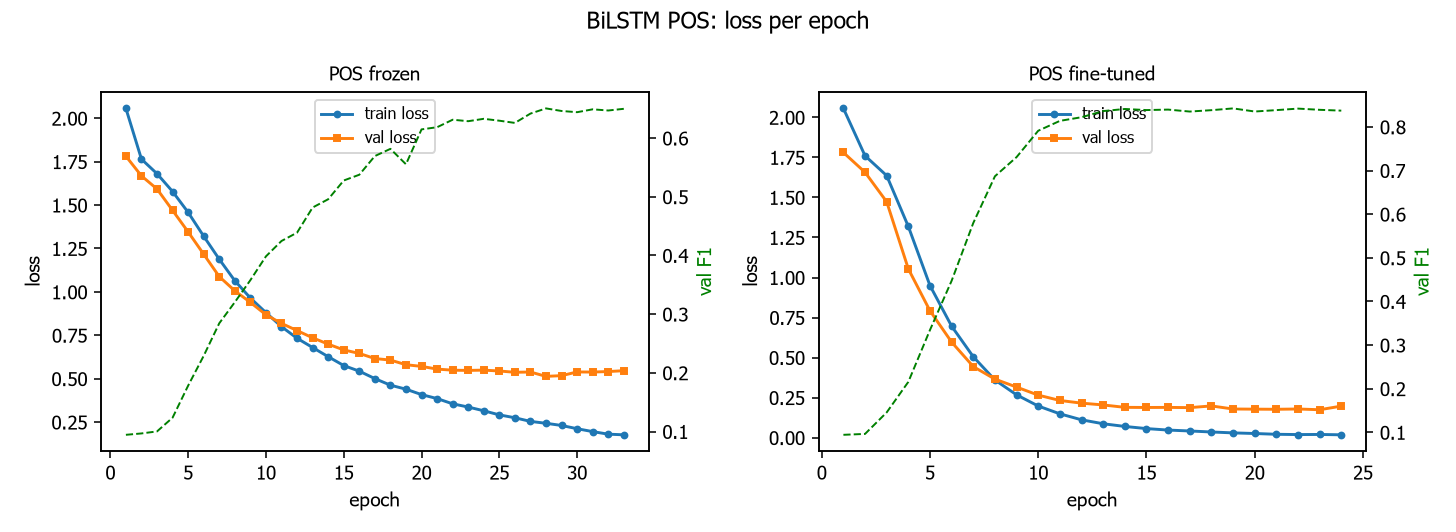

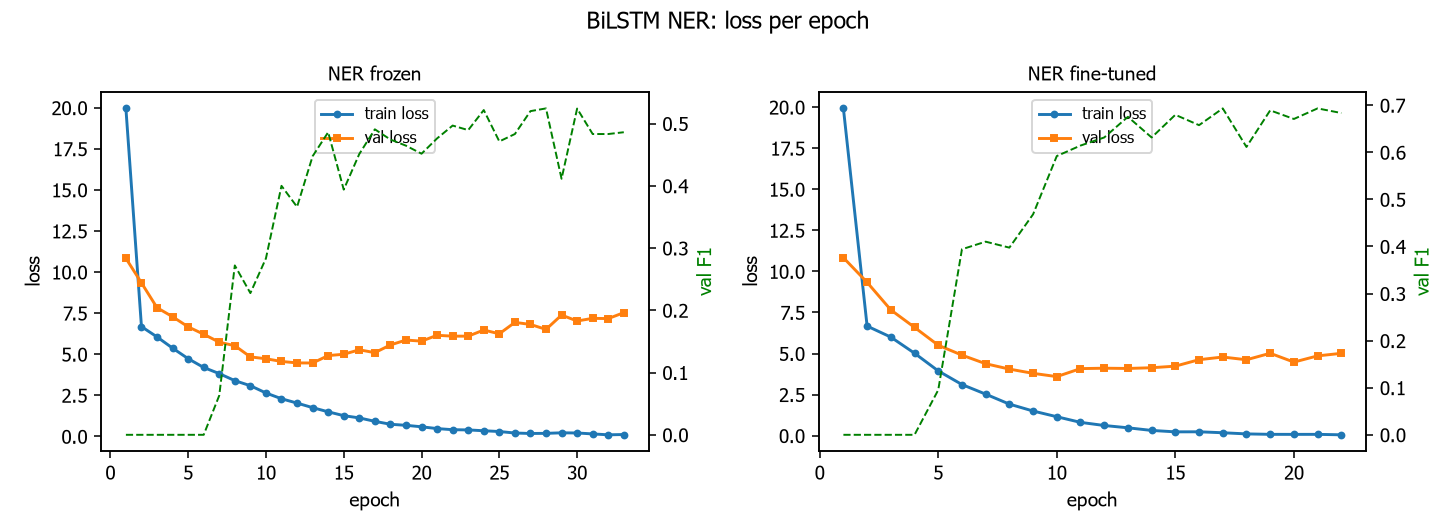

In [13]:
from src import part2_train as p2
res2 = p2.run(verbose=False)
rows = []
for task in ["pos", "ner"]:
    for mode in ["frozen", "fine-tuned"]:
        r = res2[task][mode]; t = r["test"]
        rows.append({"task": task.upper(), "embeddings": mode, "best val F1": round(r["val_f1"], 4),
                     "test acc / P": round(t.get("accuracy", t.get("precision", 0)), 4),
                     "test macro-F1 / entity F1": round(t.get("macro_f1", t.get("f1", 0)), 4),
                     "epochs run": r["epochs_run"], "best epoch": r["best_epoch"], "s/epoch": r["sec_per_epoch"]})
display(pd.DataFrame(rows))
print("Saved models use:", {t: res2[t]["best_mode"] for t in ["pos", "ner"]}, "-> models/bilstm_pos.pt, models/bilstm_ner.pt")
show(FIG_DIR / "bilstm_pos_loss.png", 900); show(FIG_DIR / "bilstm_ner_loss.png", 900)

Fine-tuning the Word2Vec initialisation is clearly better than freezing it for both tasks. The C3 vectors were trained for distributional similarity, so words with the same topic but different syntactic roles get similar vectors, and frozen inputs cannot be reshaped for tagging. Many tagging cues in this data are also lexical (closed-class words, gazetteer names), and fine-tuning lets the model sharpen exactly those vectors. The loss curves show the frozen models converging more slowly and to a higher loss. Validation loss bottoms out a few epochs before training stops, which is where the early-stopping checkpoint is taken.

## 5. Evaluation
### 5.1 POS tagging

Test token accuracy = 0.9427 | macro-F1 = 0.9206  (fine-tuned embeddings)


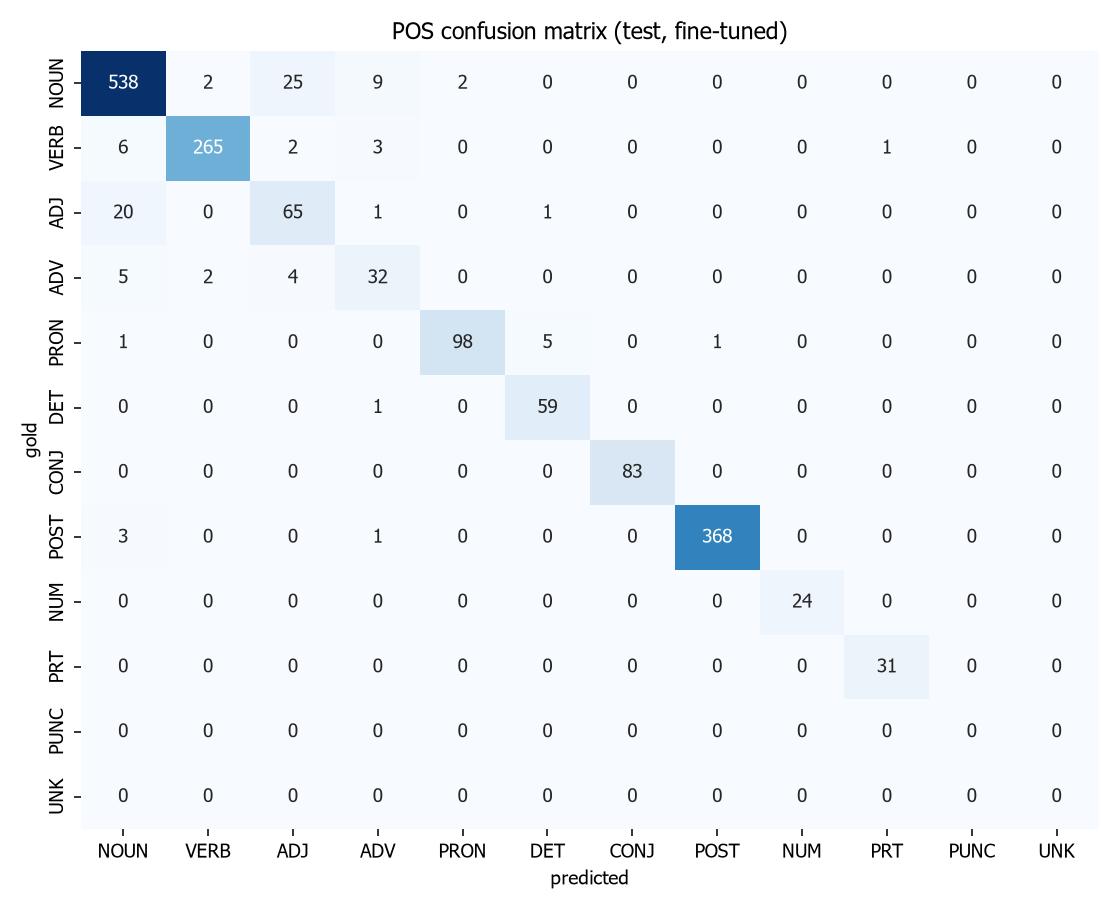

**NOUN <-> ADJ**: 45 confusions

  • اس رپورٹ کے مطابق قمیض کے پچھل حصے میں گول داخل ہون کا سوراخ تقریبا <NUM> <NUM> ملی میٹر جبکہ سامن کی جانب گول نکلن کا سوراخ تقریبا <NUM> <NUM> ملی میٹر ہے
     errors: سوراخ (gold=NOUN, pred=ADJ); سوراخ (gold=NOUN, pred=ADJ)
  • شاذ و نادر انسا گرد میں امونیم میگنیشیم فاسفیٹ کی پتھر بھی دیکھ گئی ہیں
     errors: نادر (gold=NOUN, pred=ADJ)


**NOUN <-> ADV**: 14 confusions

  • شاذ و نادر انسا گرد میں امونیم میگنیشیم فاسفیٹ کی پتھر بھی دیکھ گئی ہیں
     errors: شاذ (gold=NOUN, pred=ADV)
  • تو میں اس کے ساتھ ایسا مذاق کیس کر سکتا ہوں
     errors: مذاق (gold=NOUN, pred=ADV); کیس (gold=ADV, pred=NOUN)


**NOUN <-> VERB**: 8 confusions

  • میرا بھی بیٹا ہوتا تو وہ عالم چیمپئن بنتا
     errors: بنتا (gold=VERB, pred=NOUN)
  • انٹرنیشنل کیمپ فار تبت نے امداد کارکن کی کوشش کو سراہ ہوئ کہا کہ بیجنگ سوشل میڈیا سے ویڈیوز اور عین شاہد کی معلوم ہٹا رہا ہے
     errors: ہٹا (gold=VERB, pred=NOUN)


In [14]:
pos = res2["pos"]; best = pos[pos["best_mode"]]["test"]
print(f"Test token accuracy = {best['accuracy']:.4f} | macro-F1 = {best['macro_f1']:.4f}  ({pos['best_mode']} embeddings)")
show(FIG_DIR / "pos_confusion.png", 650)
for p in pos["confused_pairs"]:
    display(Markdown(f"**{p['pair']}**: {p['count']} confusions"))
    for e in p["examples"]:
        print("  •", e["sentence"]); print("     errors:", "; ".join(e["errors"]))

The three most confused pairs are all **open-class** pairs, and NOUN↔ADJ dominates. In Urdu, adjectives are frequently used nominally, and the Assignment 1 stemmer strips the inflectional endings (‑ی, ‑ے, ‑ا) that would otherwise separate them. Many unseen content words are labelled by default rules, so the boundary between NOUN and ADJ/ADV is inherently noisy in the silver data. NOUN↔VERB confusions come from conjunct verbs (noun + کر/ہو) and from stems that are both nominal and verbal after stemming. Closed classes (POST, PRON, CONJ, PRT, NUM) are tagged almost perfectly.

**Frozen vs fine-tuned summary**

In [15]:
pd.DataFrame({m: {"val macro-F1": pos[m]["val_f1"], "test accuracy": pos[m]["test"]["accuracy"], "test macro-F1": pos[m]["test"]["macro_f1"],
                  "epochs": pos[m]["epochs_run"]} for m in ["frozen", "fine-tuned"]}).T.round(4)

,val macro-F1,test accuracy,test macro-F1,epochs
frozen,0.6506,0.8052,0.6834,33.0
fine-tuned,0.8425,0.9427,0.9206,24.0


### 5.2 NER (entity-level, conlleval)

In [16]:
ner = res2["ner"]
print(ner["conlleval_report"])
d = ner[ner["best_mode"]]["conlleval"]
display(pd.DataFrame({k: {m: round(v[m], 4) if isinstance(v[m], float) else v[m] for m in ["precision", "recall", "f1", "gold", "pred"]} for k, v in d.items()}).T)
abl = ner["ablations"]
display(Markdown("**With vs without CRF (mean ± std over 3 seeds)**"))
pd.DataFrame({k: {"test entity F1": f"{abl[k]['test_f1_mean']:.4f} ± {abl[k]['test_f1_std']:.4f}", "val F1": round(abl[k]["val_f1_mean"], 4)}
              for k in ["Full model (fine-tuned)", "A4 softmax instead of CRF"]}).T

accuracy:  98.01%; precision:  74.29%; recall:  55.32%; FB1:  63.41
              PER: precision:  27.27%; recall:  21.43%; FB1:  24.00  11
              LOC: precision: 100.00%; recall:  76.92%; FB1:  86.96  20
              ORG: precision: 100.00%; recall:  50.00%; FB1:  66.67  1
             MISC: precision:  66.67%; recall:  40.00%; FB1:  50.00  3


,precision,recall,f1,gold,pred
PER,0.2727,0.2143,0.2400,14.0,11.0
LOC,1.0000,0.7692,0.8696,26.0,20.0
ORG,1.0000,0.5000,0.6667,2.0,1.0
MISC,0.6667,0.4000,0.5000,5.0,3.0
overall,0.7429,0.5532,0.6341,47.0,35.0


**With vs without CRF (mean ± std over 3 seeds)**

,test entity F1,val F1
Full model (fine-tuned),0.6340 ± 0.0136,0.7311
A4 softmax instead of CRF,0.6201 ± 0.0382,0.6882


**Error analysis: 5 false positives and 5 false negatives** (the gold labels are the rule-based silver annotations)

In [17]:
print(f"total FP = {ner['n_fp']}, total FN = {ner['n_fn']}")
fp = pd.DataFrame([{"predicted entity": e["entity"], "pred type": e["pred_type"], "gold": e["gold"], "sentence": e["sentence"]} for e in ner["false_positives"]])
fn = pd.DataFrame([{"missed entity": e["entity"], "gold type": e["gold_type"], "prediction": e["pred"], "sentence": e["sentence"]} for e in ner["false_negatives"]])
display(Markdown("**False positives**")); display(fp); display(Markdown("**False negatives**")); display(fn)

total FP = 9, total FN = 21


**False positives**

,predicted entity,pred type,gold,sentence
0,پی,MISC,O,رعنا کنول ایک میوزک ویڈیو بنا چاہ تھی جو انھ پی ٹی وی اکیڈم کی جانب سے بطور اسائنمنٹ دی گئی تھی
1,حسن,PER,O,وہ روحیل حیات کے ساتھ کوک سٹوڈیو میں کام کر چکے ہیں شاہ حسن نے ان کے بینڈ کے پہل البم کی ماسٹرنگ کی جب کہ جنید جمشید...
2,خان,PER,"[(عمران خان, PER)]",انھ نے کہا کہ عمران خان کا معائنہ کرن والی ٹیم نے سابق وزیر اعظم کو فٹ قرار دیا جس کے بعد انھ دوبارہ اڈیالہ جیل منتق...
3,آشا,PER,O,اپن بچپن کے دن میں لتا اور چھوٹ بہن آشا کبھ ایک دوسر سے الگ نہ ہوت آشا اپن بڑی بہن کے پیچھ سائ کی طرح چلت رہت
4,خواجہ محمد آصف,PER,"[(محمد آصف, PER)]",اس موقع پر سپیکر نے شق وار منظور لی جس کے بعد خواجہ محمد آصف نے بل منظور کے لیے پیش کیا جسے کثرت رائ سے منظور کیا گیا


**False negatives**

,missed entity,gold type,prediction,sentence
0,بیجنگ,LOC,O,انٹرنیشنل کیمپ فار تبت نے امداد کارکن کی کوشش کو سراہ ہوئ کہا کہ بیجنگ سوشل میڈیا سے ویڈیوز اور عین شاہد کی معلوم ہٹ...
1,برازیل,LOC,O,اسی طرح اس سال کے ٹورنامنٹ کے لیے روان سے قبل برازیل کی ٹیم کو دی جان والی الوداع تقریب بھی ایک طرح کا اظہار تھی
2,فلسطی,MISC,O,ابراہام نے اپن فلسطی ساتھ صحاف باسل عدرا کا ذکر کرت ہوئ کہا کہ اگرچہ وہ انہ اپنا بھائ سمجھ ہیں لیکن دون کی زند میں و...
3,باسل عدرا,PER,O,ابراہام نے اپن فلسطی ساتھ صحاف باسل عدرا کا ذکر کرت ہوئ کہا کہ اگرچہ وہ انہ اپنا بھائ سمجھ ہیں لیکن دون کی زند میں و...
4,عمران خان,PER,"[(خان, PER)]",انھ نے کہا کہ عمران خان کا معائنہ کرن والی ٹیم نے سابق وزیر اعظم کو فٹ قرار دیا جس کے بعد انھ دوبارہ اڈیالہ جیل منتق...


**Explanation of the errors**

| # | Error | Explanation |
|---|---|---|
| FP1 | `پی` → MISC (gold O) | Part of the acronym پی ٹی وی (PTV). This is a real organisation that is missing from the gazetteer, so the silver label is O. The model has seen letter-tokens such as پی in پی ایس ایل / پی ٹی آئی and tagged the first token, but it could not complete the span. |
| FP2 | `حسن` → PER (gold O) | شاہ حسن is a real musician. The gazetteer misses him and the name rules did not fire, so this "false" positive is a **correct generalisation** that the silver labels count as wrong. |
| FP3 | `خان` → PER (gold عمران خان) | Boundary error: only the surname was predicted. Under conlleval one boundary error counts as one FP **and** one FN (see FN5). |
| FP4 | `آشا` → PER (gold O) | Asha Bhosle referred to by first name only. The gazetteer has just the full name آشا بھوسلے, so the single token stayed O. The model is right and the annotation is incomplete. |
| FP5 | `خواجہ محمد آصف` → PER (gold محمد آصف) | The model includes the honorific خواجہ, which is part of the minister's full name (Khawaja Muhammad Asif). The given-name rule only covered محمد + 1 token. This is again an annotation boundary artefact. |
| FN1 | `بیجنگ` (LOC) missed | Beijing is used metonymically for the Chinese government ("Beijing is removing videos"). It is the grammatical subject with no locative postposition, and it is rare in the 350 training sentences. |
| FN2 | `برازیل` (LOC) missed | Appears in a sports context (برازیل کی ٹیم) where country names act like team names. The country is rare in training, so the model has no strong lexical cue. |
| FN3 | `فلسطی` (MISC) missed | Stemmed nationality adjective (فلسطینی → فلسطی). MISC is the smallest and most heterogeneous class, and the stemmed form barely occurs in training. |
| FN4 | `باسل عدرا` (PER) missed | Unseen foreign name. The silver label comes from the title rule (صحافی + unknown words), and the model has not learned this trigger from the few examples available. |
| FN5 | `عمران خان` (PER) | The other half of FP3: the predicted span lacks عمران, so the entity counts as missed. |

Overall, **PER is the weakest type** (F1 ≈ 0.24): person names are open-class, mostly unseen in a 350-sentence training set, and their silver labels are the noisiest. **LOC is the strongest** (F1 ≈ 0.87, precision 1.0) because a small set of countries and cities recurs constantly. Several "errors" (FP2, FP4, FP5) are cases where the BiLSTM-CRF is more correct than the rule-based annotation.

### 5.3 Ablation study
Each ablation changes one factor of the fine-tuned full model and is trained independently on the same split with 3 seeds (42, 7, 123). The table shows the mean ± std on the test set.

In [18]:
rows = []
for task in ["pos", "ner"]:
    for k, v in res2[task]["ablations"].items():
        rows.append({"task": task.upper(), "setting": k,
                     "test metric": (f"acc {v['test_acc_mean']:.4f} | macro-F1 {v['test_f1_mean']:.4f} ± {v['test_f1_std']:.4f}" if task == "pos"
                                     else f"entity F1 {v['test_f1_mean']:.4f} ± {v['test_f1_std']:.4f}"),
                     "val F1": round(v["val_f1_mean"], 4), "epochs": round(v["epochs_mean"], 1)})
pd.DataFrame(rows)

,task,setting,test metric,val F1,epochs
0,POS,Full model (fine-tuned),acc 0.9453 | macro-F1 0.9286 ± 0.0057,0.8476,24.3
1,POS,A1 unidirectional LSTM,acc 0.9258 | macro-F1 0.8890 ± 0.0108,0.8206,29.7
2,POS,A2 no dropout,acc 0.9467 | macro-F1 0.9307 ± 0.0044,0.8505,23.7
3,POS,A3 random embedding init,acc 0.9009 | macro-F1 0.8677 ± 0.0058,0.8023,27.0
4,NER,Full model (fine-tuned),entity F1 0.6340 ± 0.0136,0.7311,22.3
5,NER,A1 unidirectional LSTM,entity F1 0.5358 ± 0.0389,0.5899,26.7
6,NER,A2 no dropout,entity F1 0.6425 ± 0.0170,0.6977,19.7
7,NER,A3 random embedding init,entity F1 0.5808 ± 0.0173,0.5984,22.0
8,NER,A4 softmax instead of CRF,entity F1 0.6201 ± 0.0382,0.6882,38.7


**Discussion of each ablation** (the full model is the fine-tuned BiLSTM with CRF for NER; differences are in F1 points)

* **A1, unidirectional LSTM:** the largest drop for NER (≈ −9.8 F1) and a clear drop for POS (≈ −4.0 macro-F1). Urdu is head-final, so the cues that identify a token often come **after** it: postpositions (کے، نے، میں) decide whether the preceding word is a noun, auxiliaries decide verbs, and suffix nouns or titles mark entity boundaries. A left-to-right LSTM cannot see them, so backward context is essential.
* **A2, no dropout:** no significant change (POS +0.2, NER +0.9, both within one standard deviation across seeds). With early stopping on validation F1 and only ~7.7k training tokens, training stops before heavy overfitting, so dropout between LSTM layers adds little here. It would matter more with longer training or larger hidden sizes.
* **A3, random embedding initialisation:** a consistent drop for both tasks (POS ≈ −6.1, NER ≈ −5.3) and slower convergence. The C3 Word2Vec vectors carry distributional knowledge from the full 460k-token corpus, while the tagger sees only 350 sentences. Rare words in the test set therefore have meaningful vectors only when pre-trained.
* **A4, softmax instead of CRF:** a smaller drop (≈ −1.4 entity F1) but much higher variance across seeds (std 0.038 vs 0.014). It also needs far more epochs to converge (≈ 39 vs 22). Without the transition matrix the softmax decoder can emit invalid sequences (O → I-PER, B-LOC → I-ORG), which conlleval turns into broken or extra entities. The CRF enforces consistent BIO structure, which helps most for multi-token names.

# Part 3: Transformer encoder for topic classification
## 6. Dataset preparation
Each article gets its topic label (see the top of the notebook). It is represented as the token-ID sequence of its cleaned text using the shared `word2idx.json`, truncated or padded to **256 tokens**, and the data are split 70/15/15 stratified by category.

## 7. Transformer encoder (`src/transformer.py`)
Each component is a separate `nn.Module`:
* `ScaledDotProductAttention`: softmax(QKᵀ/√d_k)V with an optional key-padding mask; returns the output **and** the attention weights.
* `MultiHeadSelfAttention`: h = 4 heads, d_model = 128, d_k = d_v = 32, **separate W_Q, W_K, W_V per head** (`ModuleList`) and a shared output projection W_O.
* `PositionwiseFeedForward`: Linear(128→512), ReLU, Linear(512→128).
* `SinusoidalPositionalEncoding`: fixed buffer (`register_buffer`, not a parameter), added to the scaled embeddings.
* `EncoderBlock` ×4 with **Pre-LN**: x ← x + Dropout(MHA(LN(x))); x ← x + Dropout(FFN(LN(x))).
* `TransformerClassifier`: a learned **[CLS]** vector is prepended; its final representation (after LayerNorm) goes through an MLP 128 → 64 → 5.

Training uses AdamW (η = 5×10⁻⁴, weight decay 0.01), a cosine schedule with 50 warm-up steps, 20 epochs and batch 16. The checkpoint with the best validation accuracy is kept.

,Politics,Sports,Economy,International,Health & Society,total
train,34,66,8,38,64,210
val,7,14,2,8,14,45
test,7,14,2,9,13,45


Transformer parameters: 2,082,309 | BiLSTM classifier parameters: 1,632,269


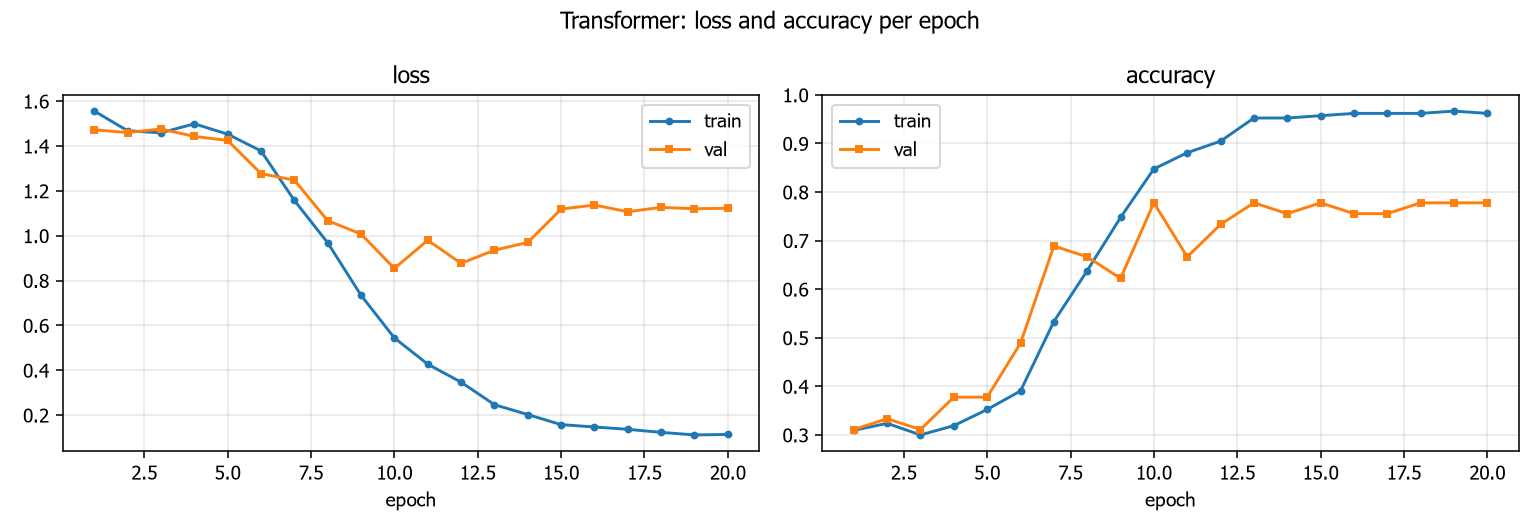

In [19]:
from src import part3_train as p3
res3 = p3.run(verbose=False)
display(pd.DataFrame(res3["class_distribution"]).T.assign(total=lambda d: d.sum(1)))
print("Transformer parameters:", f"{res3['n_params_transformer']:,}", "| BiLSTM classifier parameters:", f"{res3['n_params_bilstm']:,}")
show(FIG_DIR / "transformer_curves.png", 900)

## 8. Evaluation
### 8.1 Results

Transformer  test accuracy = 0.6444 | macro-F1 = 0.5082


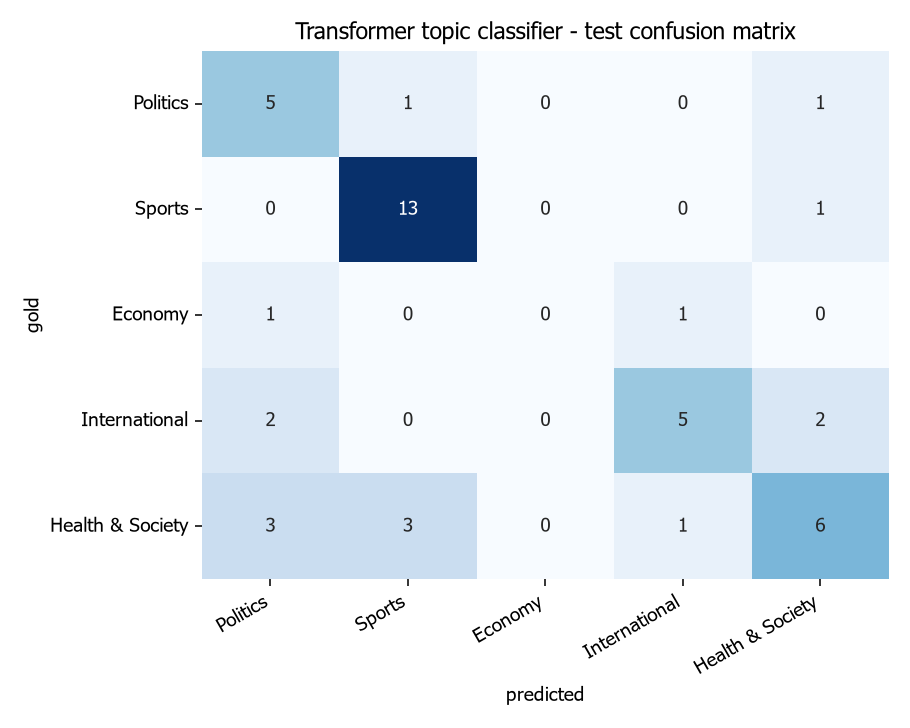

In [20]:
t = res3["transformer"]["test"]
print(f"Transformer  test accuracy = {t['accuracy']:.4f} | macro-F1 = {t['macro_f1']:.4f}")
show(FIG_DIR / "transformer_confusion.png", 560)

**Attention heatmaps.** The figure shows three correctly classified test articles from different classes. The left and middle panels are heads 1 and 2 of the **final** encoder layer over the first 30 positions ([CLS] and tokens). The right panel shows which tokens [CLS] attends to most across the whole 256-token input (mean of the 4 heads).

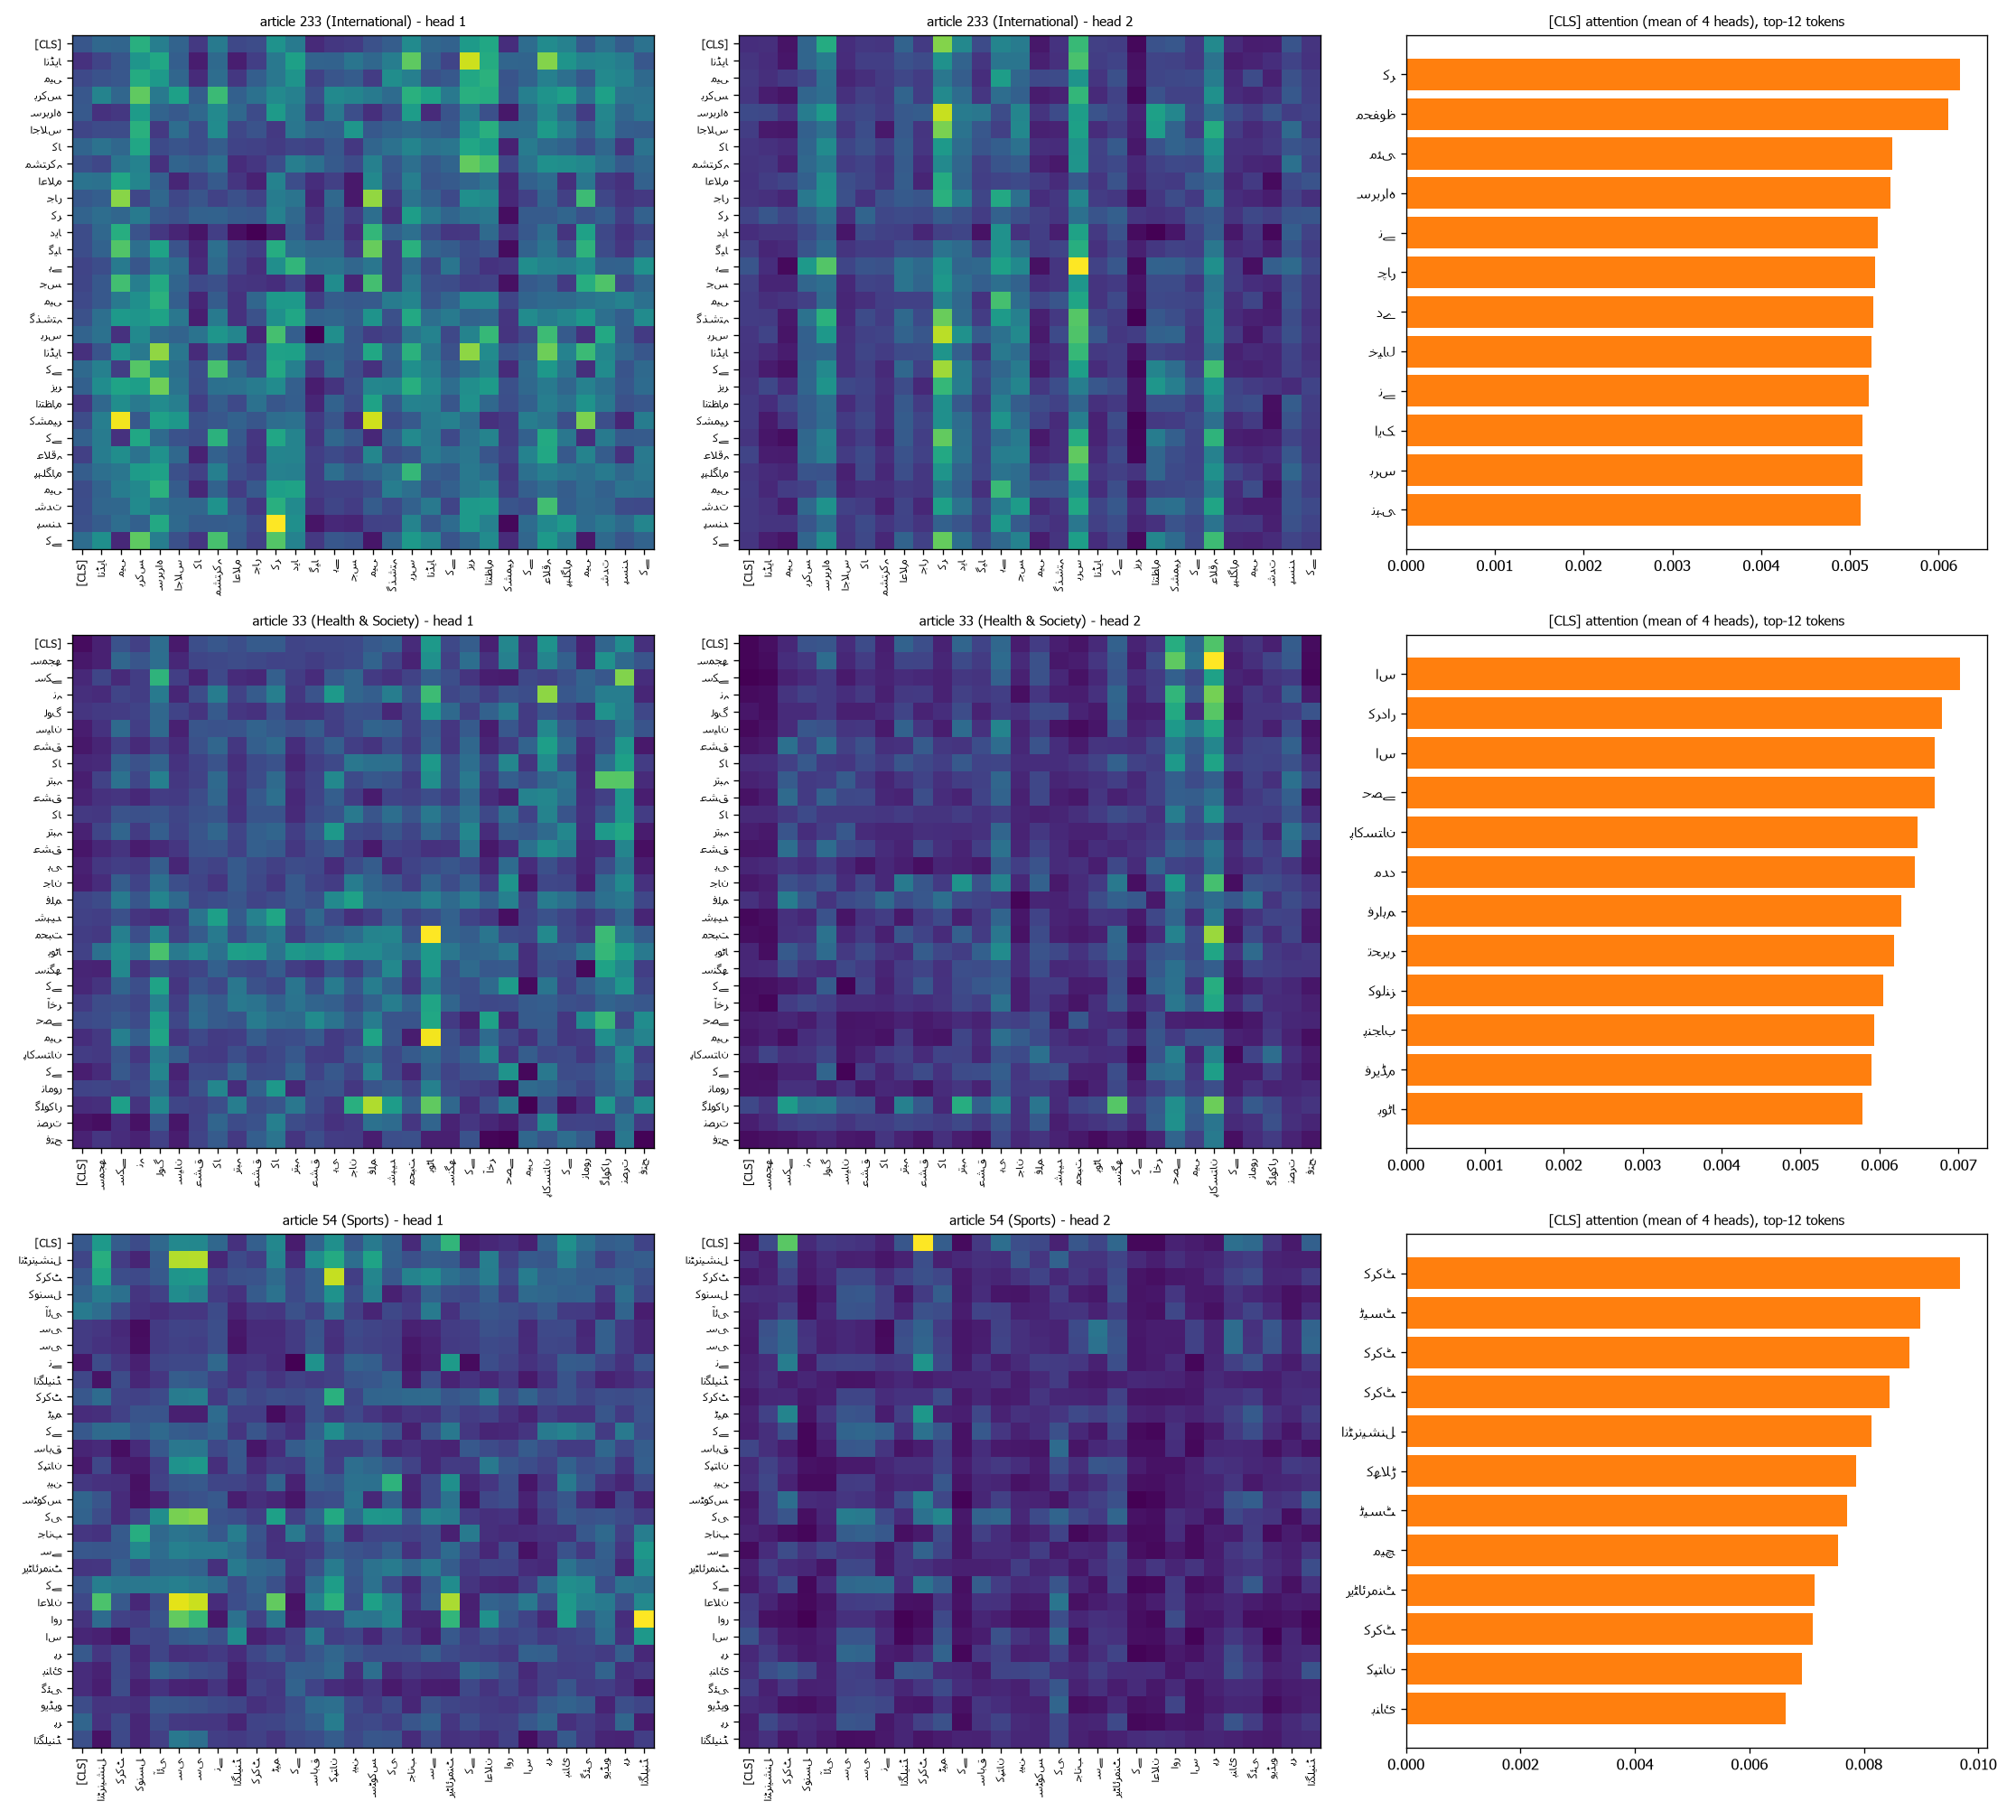

article 233 (International): پہلگام حملے کی مذمت اور فلسطین کا ذکر: برکس ممالک کا ’نئی دہلی اعلامیہ‘ جسے انڈیا نے اپنی سفارتی کامیابی قرار دیا
   [CLS] top tokens: کر، محفوظ، مئی، سربراہ، نے، چار، دے، خیال
   per-head top-5: {'head1': ['مئی', 'خیال', 'واقع', 'بعد', 'چار'], 'head2': ['محفوظ', 'کر', 'نے', 'ایک', 'برس'], 'head3': ['دستخط', 'کیا', 'دے', '<NUM>', 'اجلاس'], 'head4': ['محفوظ', 'کر', 'زیر', 'زیر', 'قرار']}
article 33 (Health & Society): 1500 روپے کا سودا، مذہب کی تبدیلی اور لاہور ریلوے سٹیشن پر خودکشی: ’بوٹا سنگھ اور زینب‘ حقیقت میں کون تھے؟
   [CLS] top tokens: اس، کردار، اس، حصے، پاکستان، مدد، فراہم، تحریر
   per-head top-5: {'head1': ['فریڈم', 'بوٹا', 'بوٹا', 'وقت', 'کولنز'], 'head2': ['پاکستان', 'اس', 'حصے', 'اس', 'فراہم'], 'head3': ['لوگ', 'تقریبا', 'ایک', 'آئی', 'پیشکش'], 'head4': ['میں', 'پنجاب', 'بنیاد', 'مدد', 'فیچرز']}
article 54 (Sports): بین سٹوکس کا آئی سی سی پر طنز: ڈریسنگ روم میں بنائی گئی ریٹائرمنٹ کی ویڈیو پر تنازع کیوں ہوا؟
   [CLS] top tokens: کرکٹ، ٹیسٹ، کر

In [21]:
show(FIG_DIR / "transformer_attention.png", 1000)
for a in res3["transformer"]["attention_articles"]:
    print(f"article {a['article']} ({a['label']}): {res3['attention_article_titles'][str(a['article'])] if str(a['article']) in res3['attention_article_titles'] else res3['attention_article_titles'].get(a['article'], '')}")
    print("   [CLS] top tokens:", "، ".join(w for w, _ in a["cls_top_tokens"][:8]))
    print("   per-head top-5:", a["per_head_cls_top5"])

### 8.2 BiLSTM vs Transformer comparison
A 2-layer BiLSTM classifier (C3 Word2Vec initialisation, fine-tuned, max-pooling over time) is trained on the same split for 20 epochs so the comparison is like-for-like.

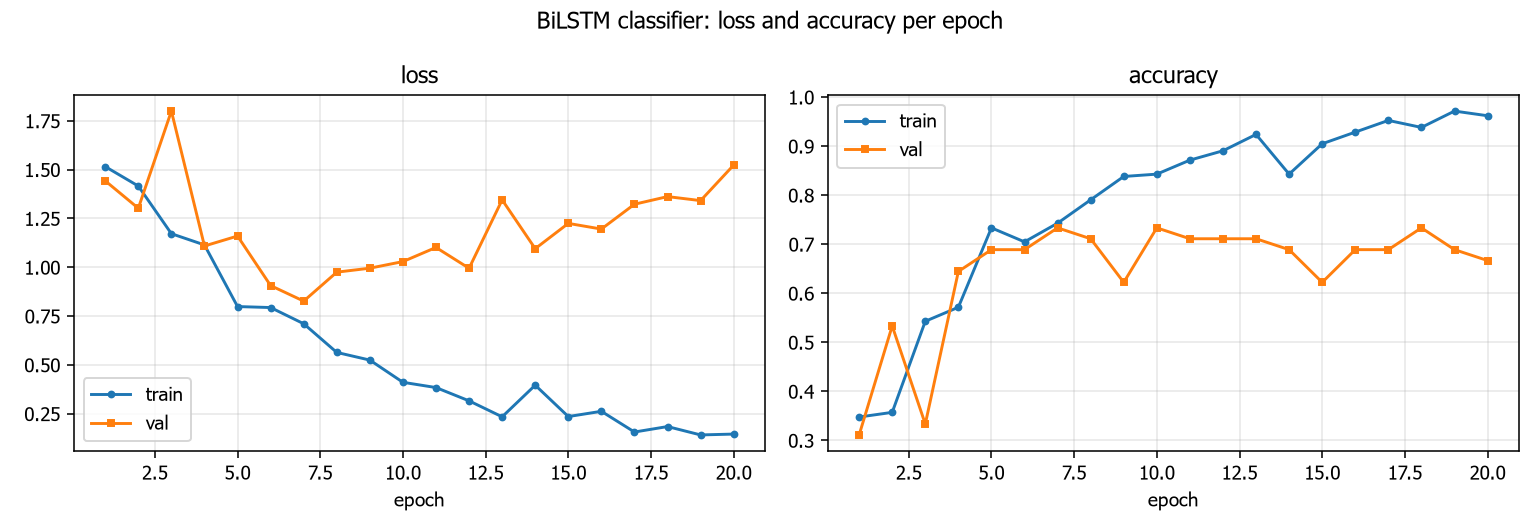

,Transformer,BiLSTM
test accuracy,6.444000e-01,6.667000e-01
test macro-F1,5.082000e-01,5.036000e-01
best-val epoch,1.000000e+01,7.000000e+00
s / epoch,8.750000e+00,1.890000e+00
parameters,2.082309e+06,1.632269e+06


Accuracy difference (Transformer - BiLSTM) = -2.2 points; macro-F1 difference = +0.5 points


In [22]:
b, tr = res3["bilstm"], res3["transformer"]
show(FIG_DIR / "bilstm_cls_curves.png", 900)
cmp = pd.DataFrame({"Transformer": {"test accuracy": tr["test"]["accuracy"], "test macro-F1": tr["test"]["macro_f1"],
                                    "best-val epoch": tr["best_val_epoch"], "s / epoch": tr["sec_per_epoch"], "parameters": res3["n_params_transformer"]},
                    "BiLSTM": {"test accuracy": b["test"]["accuracy"], "test macro-F1": b["test"]["macro_f1"],
                               "best-val epoch": b["best_val_epoch"], "s / epoch": b["sec_per_epoch"], "parameters": res3["n_params_bilstm"]}})
display(cmp.round(4))
diff = tr["test"]["accuracy"] - b["test"]["accuracy"]
print(f"Accuracy difference (Transformer - BiLSTM) = {100*diff:+.1f} points; macro-F1 difference = {100*(tr['test']['macro_f1']-b['test']['macro_f1']):+.1f} points")

**Answers to the five questions**

1. **Accuracy.** The BiLSTM classifier is slightly more accurate: **66.7 % vs 64.4 %** (−2.2 points for the Transformer). Macro-F1 is essentially tied (0.504 vs 0.508), so with a 45-article test set the two models are statistically indistinguishable; one article is worth 2.2 points.
2. **Convergence.** The BiLSTM converged in fewer epochs. Its best validation accuracy came at **epoch 7**, the Transformer's at **epoch 10**. The Transformer stays near chance (≈ 31 % validation accuracy) for the first ~5 epochs while its randomly initialised embeddings and attention weights organise, whereas the BiLSTM starts from pre-trained Word2Vec vectors.
3. **Training speed.** The BiLSTM was about **4–5× faster per epoch** (≈ 1.9 s vs ≈ 8.8 s on CPU). Self-attention is quadratic in sequence length: every layer builds 257 × 257 attention matrices for 4 heads in 4 layers. This implementation also computes each head with its own separate projection matrices in a Python loop, as the specification requires, instead of one fused matrix multiplication. The LSTM is a single optimised fused kernel that is linear in sequence length.
4. **Attention heatmaps.** In the final layer, [CLS] attends strongly to topical content words. For the Sports article every head concentrates on کرکٹ، ٹیسٹ، کھلاڑی، میچ، انٹرنیشنل (head 2 almost exclusively on کرکٹ), which is exactly the keyword evidence for the label. For the International article, one head picks out treaty vocabulary (دستخط "signed", اجلاس "meeting"), while other heads attend to frequent function and verb tokens (کر، نے) and dates. The token-to-token maps show vertical stripes, i.e. many positions attending to the same few "hub" tokens, and some heads stay close to uniform. Attention is interpretable for strongly topical articles and more diffuse for the mixed Health & Society class, which is also where most confusions occur.
5. **Small data (200–300 articles).** The **BiLSTM is the more appropriate architecture.** It has a stronger sequential inductive bias, fewer effective degrees of freedom, and can start from pre-trained embeddings. The Transformer has to learn token interactions from scratch and needs much more data for that flexibility to pay off. Both models overfit here (training accuracy ≈ 97 % while validation loss rises after epochs 7–13), but the BiLSTM gets there faster and more cheaply. A Transformer becomes preferable with thousands of documents or with pre-training, which the assignment rules exclude.

---
**Artefacts produced by this notebook:** `embeddings/{tfidf_matrix,ppmi_matrix,embeddings_w2v}.npy`, `embeddings/word2idx.json`, `models/{bilstm_pos,bilstm_ner,transformer_cls}.pt`, `data/{pos,ner}_{train,val,test}.conll`, all figures in `outputs/figures/` and all metrics in `outputs/results/*.json`.

**Repository:** https://github.com/SarmadRazaq/i24-7709-NLP-Assignment2